### This code illustrates how to compute the self-part of Van Hove function in order to decribe the dynamics of CO2 within ionic liquid system

### Prerequisite:
* CoordinationNumbers

### Package Required:
* numpy
* mdtraj
* matplotlib

### Note: If you don't have the packages listed above installed, then you can type in the following commands in the terminal
* conda install numpy
* conda install -c conda-forge mdtraj
* conda install matplotlib

### File Required:
* A trajectory file (.h5 or .dcd)
* A toplogy file (.pdb)

* Note: Here, I use a trajectory that contains only one CO2 molecule as an example
    *  /pikachu/homes/zhuo/haverford/code_example/EMIM_NTF2.dcd
    *  /pikachu/homes/zhuo/haverford/code_example/EMIM_NTF2.pdb

### Background:

* The van Hove correlation function $G_s(\vec{r}, t)$ describes the evolution of the particle motion according to:
* $$G_s(\vec{r}, t) = \langle \delta(\vec{r}_i(t_0 + t) - \vec{r}_i(t_0) - \vec{r})\rangle$$
* It represents the probability of a particle moves at a certain distance $r$ in a time interval $t$. At short time intervals, this can be used to visualize how the $CO_2$ is trapped in a local environment. At long time intervals, this can be used to capture how far $CO_2$ has transported in the system. 

### The Code:

1. Import the required package

In [66]:
import numpy as np
import mdtraj as md
import matplotlib.pyplot as plt
import os
import math

2. Load the trajectory file 

In [67]:
traj = md.load('/pikachu/homes/zhuo/haverford/code_example/EMIM_NTF2.dcd',top='/pikachu/homes/zhuo/haverford/code_example/EMIM_NTF2.pdb')
topology = traj.topology
traj
topology

<mdtraj.Topology with 3 chains, 522 residues, 8734 atoms, 8468 bonds at 0x7eff328b8530>

3. Calculate the center of mass for each CO2 molecule in each frame

In [68]:
pos_com = []
res_name = "OCO"
for i, res in enumerate(topology.residues):
    if res.name == res_name:
        atom_indices = [atom.index for atom in res.atoms]
        subtraj = traj.atom_slice(atom_indices)
        com = md.compute_center_of_mass(subtraj)
        pos_com.append(com)
xyz = np.asarray(pos_com).transpose(1, 0, 2)

4. Define the time separation (Note: the time separation has to be no less than the timestep of the collected trajectory)

In [69]:
timestep = 10 # in ps
tau = 10 # in ps
tau_in_frame = tau//timestep # number of frames in each tau

5. Calculate the displacement of CO2 

In [70]:
disp = xyz[tau_in_frame:] - xyz[:-tau_in_frame]
disp = np.array(np.linalg.norm(disp, axis=-1))
disp = disp.flatten() # Turn the array into 1D

6. Plot the displacement histogram

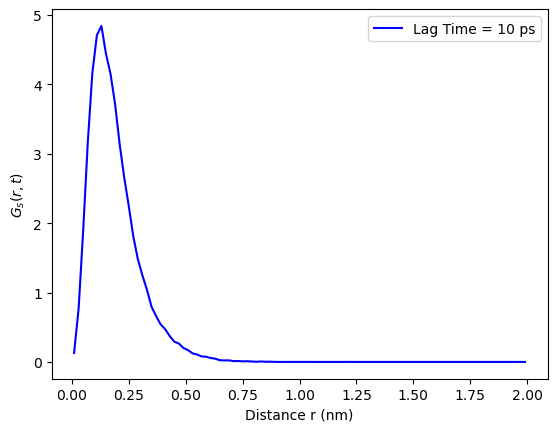

In [71]:
counts, bin_edges = np.histogram(disp, bins=100, range=(0, 2), density=True)
r = (bin_edges[:-1] + bin_edges[1:]) / 2
plt.plot(r, counts, label=f'Lag Time = {tau} ps',color="blue")
plt.xlabel('Distance r (nm)')
plt.ylabel(r'$G_s(r, t)$')
plt.legend()
plt.show()

7. Let's try a different time separation to see the difference

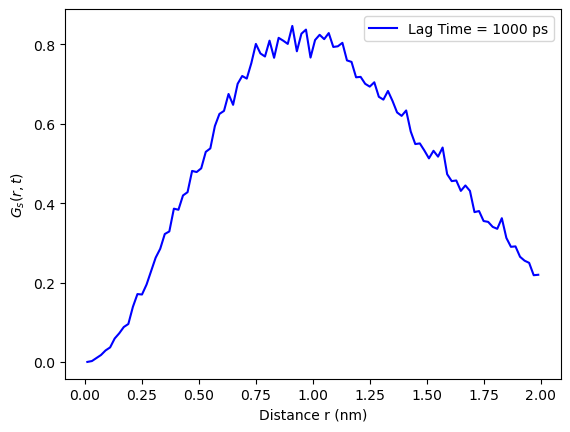

In [72]:
tau = 1000 # in ps
tau_in_frame = tau//timestep # number of frames in each tau
disp = xyz[tau_in_frame:] - xyz[:-tau_in_frame]
disp = np.array(np.linalg.norm(disp, axis=-1))
disp = disp.flatten() # Turn the array into 1D
counts, bin_edges = np.histogram(disp, bins=100, range=(0, 2), density=True)
r = (bin_edges[:-1] + bin_edges[1:]) / 2
plt.plot(r, counts, label=f'Lag Time = {tau} ps',color="blue")
plt.xlabel('Distance r (nm)')
plt.ylabel(r'$G_s(r, t)$')
plt.legend()
plt.show()